# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Epinnn14/Flyrank-ML-Intern/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

**How the queue is built.** I use the window-aligned feature set from `w06_validation_audit` with a
**logistic regression**. On the same client-grouped folds it gave a steadier top-of-list than the
random forest (precision@50 0.74–0.92 per fold vs 0.36–0.76; full comparison in `capstone.ipynb`),
and its weights are readable. It is trained on *days 31–90 back → did days 1–30 decline?* and then applied **one window forward**
(*days 1–60 back → will the next 30 days decline?*). So `risk_next30` is a forward-looking review
priority, not a description of the past. Every page is scored by a model that never saw its client
(5-fold, grouped by client).

**Ranking:** pages are grouped by action tier first (refresh > snippet fix > light refresh > prune
review > protect > monitor). Inside a tier they are ordered by `priority_score = risk × (1 + value at
stake)`, where value at stake is log(recent clicks + 1% of recent impressions). A risky page with
real traffic therefore comes before a risky page nobody visits.

**Reason codes** are plain rules, so an editor can see *why* a page is on the list:

| Code | Rule | What it tells the editor |
|---|---|---|
| `high_model_risk` | risk in the top 20% | the model expects a decline next month |
| `already_slipping` | last-30 impressions ≥ 20% below previous-30 | the drop has already started |
| `demand_still_there` | ≥ 300 impressions in the last 30 days | still worth saving |
| `thin_page` | < 2,000 words | room to add depth |
| `decay_age_zone` | 270–540 days old | the age range the FlyRank paper flags |
| `snippet_underperforms` | position 1–20 and CTR below its tier median (≥ 500 impressions) | title/meta problem, not content |
| `near_zero_demand` | < 10 impressions last 30 days and ≥ 1 year old | consider merge/prune, human only |

**Archetype → action mapping:** `expand_and_refresh` (risky + demand + thin), `refresh_now`
(risky + demand), `rewrite_title_and_meta` (snippet underperforms), `light_refresh_or_monitor`
(risky, little demand), `consolidate_or_prune_review` (near-zero demand, old), `protect` (healthy
with demand), `monitor` (everything else).

**Decay / refresh insight (observed, not causal).** In this slice the share of declining pages is
**highest for younger pages** (≈63% at 90–180 days) and lower at 271–540 days (≈42–47%). That is
the opposite of the paper's "decay after 270 days" curve. Our label is 30-day momentum, and young
pages swing more. Pages updated in the last 30 days declined *less* often (≈51% vs ≈61% for 91–180
days since update), but updates were **chosen** by editors, so part of that gap is the choosing. I
read it as "refreshing is worth testing", not "refreshing works".

Per-fold precision@50 (held-out clients): [0.82, 0.9, 0.74, 0.84, 0.92] -> mean 0.844
Scored 30,000 pages | backtest base rate 0.542 | backtest precision@50 0.880, @200 0.840



Action mix across all pages:
archetype_action
monitor                        14715
protect                         6747
refresh_now                     3991
rewrite_title_and_meta          2212
light_refresh_or_monitor        1366
consolidate_or_prune_review      849
expand_and_refresh               120

Top 15 of the review queue (public-safe columns only):
 rank archetype_action  risk_next30  impressions_last_30d  clicks_last_30d  content_age_days  word_count    content_type                                                                             reason_codes
    1      refresh_now         0.95                212015                8                98      3530.0 keyword article                                                       high_model_risk|demand_still_there
    2      refresh_now         0.94                122303               10               148      4939.0 keyword article                                                       high_model_risk|demand_still_there
    3   

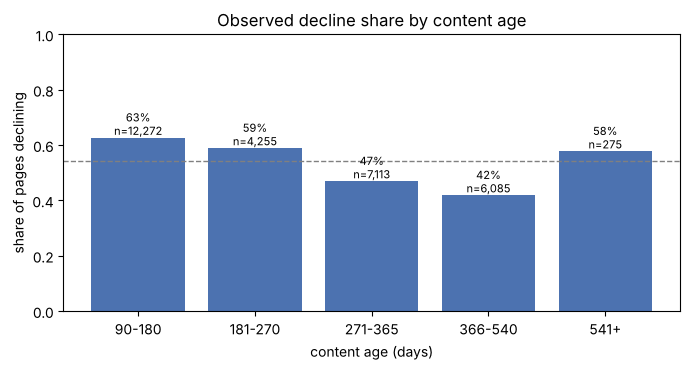

In [1]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import os, sys, subprocess, json, warnings
warnings.filterwarnings("ignore", category=UserWarning)
REPO_DIR = "Flyrank-ML-Intern"
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Epinnn14/Flyrank-ML-Intern"
if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("../..")
sys.path.insert(0, "scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ml_utils as mu
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42
os.makedirs("work/figures", exist_ok=True); os.makedirs("work/outputs", exist_ok=True)

# ---- data (same cleaning as w05/w06) ----
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
for col in mu.NUMERIC_COLUMNS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
for col in mu.CATEGORICAL_COLUMNS:
    df[col] = df[col].fillna("unknown").astype(str).replace({"": "unknown", "nan": "unknown"})
df = df[(df["impressions_90d"] > 0) & (df["content_age_days"] >= 90)].drop_duplicates("content_id").reset_index(drop=True)
df["is_declining_label"] = (df["trend_direction"] == "down").astype(int)
for c in ["impressions", "clicks", "sessions"]:
    df[f"{c}_first30"] = (df[f"{c}_90d"] - df[f"{c}_last_30d"].fillna(0) - df[f"{c}_prev_30d"].fillna(0)).clip(lower=0)

# ---- the window-aligned model from w06 ----
# TRAINING view: features from days 31-90 back  ->  label = change from days 31-60 to days 1-30.
# SCORING view (today): shift everything 30 days forward -> features from days 1-60 back
#                       -> score = risk that the NEXT 30 days decline vs the last 30.
def window_features(frame, recent, earlier, age_shift):
    out = pd.DataFrame(index=frame.index)
    for c in ["search_volume", "competition", "cpc", "word_count"]:
        out[c] = frame[c]
    out["has_search_volume"] = frame["search_volume"].notna().astype(int)
    out["has_word_count"] = frame["word_count"].notna().astype(int)
    out["content_age_days"] = frame["content_age_days"] - age_shift
    for c in ["impressions", "clicks", "sessions"]:
        out[f"log_{c}_recent"] = np.log1p(frame[recent[c]].fillna(0))
        out[f"log_{c}_earlier"] = np.log1p(frame[earlier[c]].fillna(0))
    out["early_momentum"] = out["log_impressions_recent"] - out["log_impressions_earlier"]
    cats = pd.get_dummies(frame[["competition_level", "content_type", "main_intent"]].astype(str), dtype=float)
    return pd.concat([out.fillna(0), cats], axis=1)

train_view = window_features(df, {c: f"{c}_prev_30d" for c in ["impressions", "clicks", "sessions"]},
                                 {c: f"{c}_first30" for c in ["impressions", "clicks", "sessions"]}, age_shift=30)
score_view = window_features(df, {c: f"{c}_last_30d" for c in ["impressions", "clicks", "sessions"]},
                                 {c: f"{c}_prev_30d" for c in ["impressions", "clicks", "sessions"]}, age_shift=0)
score_view = score_view[train_view.columns]
y = df["is_declining_label"].to_numpy(); groups = df["client_id"].to_numpy()

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def make_model():
    # Logistic regression on the window-aligned features: on the same client-grouped folds it gave a
    # more stable top-of-list than the random forest (see capstone.ipynb, section 4), and it is readable.
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

# Out-of-fold: every page is scored by a model that never saw its CLIENT.
df["risk_next30"] = np.nan
oof_backtest = np.zeros(len(df))
fold_p50 = []
for tr, te in GroupKFold(5).split(train_view, y, groups):
    m = make_model().fit(train_view.iloc[tr], y[tr])
    fold_p50.append(mu.precision_at_k(y[te], m.predict_proba(train_view.iloc[te])[:, 1], 50))
    oof_backtest[te] = m.predict_proba(train_view.iloc[te])[:, 1]          # for the validated precision numbers
    df.loc[df.index[te], "risk_next30"] = m.predict_proba(score_view.iloc[te])[:, 1]  # forward-looking queue score
df["risk_backtest"] = oof_backtest
print(f"Per-fold precision@50 (held-out clients): {np.round(fold_p50, 2).tolist()} -> mean {np.mean(fold_p50):.3f}")
print(f"Scored {df['risk_next30'].notna().sum():,} pages | backtest base rate {y.mean():.3f} | "
      f"backtest precision@50 {mu.precision_at_k(y, oof_backtest, 50):.3f}, @200 {mu.precision_at_k(y, oof_backtest, 200):.3f}")

# ---- transparent reason codes (the 'why' a human reads) ----
pos = df["avg_position"].where(df["avg_position"] > 0)
tier_ctr_median = df.assign(p=pos).groupby("position_tier")["ctr"].transform("median")
reasons = {
    "high_model_risk":      df["risk_next30"] >= df["risk_next30"].quantile(0.80),
    "already_slipping":     (np.log1p(df["impressions_last_30d"].fillna(0)) - np.log1p(df["impressions_prev_30d"].fillna(0))) < -0.22,
    "demand_still_there":   df["impressions_last_30d"].fillna(0) >= 300,
    "thin_page":            df["word_count"].fillna(99999) < 2000,
    "decay_age_zone":       df["content_age_days"].between(270, 540),
    "snippet_underperforms":pos.between(1, 20) & (df["ctr"] < tier_ctr_median) & (df["impressions_90d"] >= 500),
    "near_zero_demand":     (df["impressions_last_30d"].fillna(0) < 10) & (df["content_age_days"] >= 365),
}
R = pd.DataFrame(reasons)
df["reason_codes"] = R.apply(lambda r: "|".join([k for k, v in r.items() if v]) or "none", axis=1)

# ---- archetype -> action mapping (rules, in priority order) ----
def action(r):
    if r.near_zero_demand:                                   return "consolidate_or_prune_review"
    if r.high_model_risk and r.demand_still_there and r.thin_page:  return "expand_and_refresh"
    if r.high_model_risk and r.demand_still_there:           return "refresh_now"
    if r.snippet_underperforms:                               return "rewrite_title_and_meta"
    if r.high_model_risk:                                     return "light_refresh_or_monitor"
    if r.demand_still_there:                                  return "protect"
    return "monitor"
df["archetype_action"] = R.apply(action, axis=1)
ACTION_PRIORITY = {"expand_and_refresh": 1, "refresh_now": 1, "rewrite_title_and_meta": 2,
                   "light_refresh_or_monitor": 3, "consolidate_or_prune_review": 4, "protect": 5, "monitor": 6}

# value proxy: recent clicks at stake (log scale so one giant page doesn't swamp the queue)
df["value_at_stake"] = np.log1p(df["clicks_last_30d"].fillna(0) + 0.01 * df["impressions_last_30d"].fillna(0))
df["priority_score"] = df["risk_next30"] * (1 + df["value_at_stake"])
queue = df.assign(tier=df["archetype_action"].map(ACTION_PRIORITY)).sort_values(["tier", "priority_score"], ascending=[True, False])
queue["rank"] = np.arange(1, len(queue) + 1)

print("\nAction mix across all pages:")
print(df["archetype_action"].value_counts().to_string())
print("\nTop 15 of the review queue (public-safe columns only):")
show = ["rank", "archetype_action", "risk_next30", "impressions_last_30d", "clicks_last_30d", "content_age_days", "word_count", "content_type", "reason_codes"]
print(queue[show].head(15).round(2).to_string(index=False))

# ---- decay / refresh insight (observed, not causal) ----
age_bins = pd.cut(df["content_age_days"], [89, 180, 270, 365, 540, 2000], labels=["90-180", "181-270", "271-365", "366-540", "541+"])
decay = df.groupby(age_bins, observed=True)["is_declining_label"].agg(["mean", "size"]).rename(columns={"mean": "share_declining", "size": "n"})
print("\nShare of pages declining by content age (observed):")
print(decay.round(3))
upd = df.groupby("freshness_tier")["is_declining_label"].agg(["mean", "size"]).rename(columns={"mean": "share_declining", "size": "n"})
print("\nShare declining by freshness tier (measured at export; updates were CHOSEN, so read with care):")
print(upd.round(3))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(decay.index.astype(str), decay["share_declining"], color="#4C72B0")
for i, (v, n) in enumerate(zip(decay["share_declining"], decay["n"])):
    ax.text(i, v + 0.01, f"{v:.0%}\nn={n:,}", ha="center", fontsize=8)
ax.axhline(y.mean(), ls="--", color="grey", lw=1); ax.set_ylim(0, 1)
ax.set_ylabel("share of pages declining"); ax.set_xlabel("content age (days)")
ax.set_title("Observed decline share by content age")
plt.tight_layout(); plt.savefig("work/figures/w07_decay_by_age.png", dpi=150); plt.show()

## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

**Intended use.** Ordering a weekly **human review queue** for an SEO/content team: which pages to
look at first, and what kind of fix to consider. It supports a decision; it does not make one.

**Who:** a content editor or SEO lead with roughly 50 review slots per week.

**Where it stops being valid (measured in the cell below):**

- **High-traffic pages ("excellent" impression tier, n≈1,100):** lift over base rate is +0.19,
  but these pages carry the most value and a wrong call costs the most, so they always get a
  named human sign-off.
- **Content type:** lift is largest on feedly articles (+0.35 over a low 0.29 base rate) and about
  +0.15 on keyword and comparison articles. Comparison articles are only ~700 pages, so that number
  is fragile.
- **Missing data:** 8% of pages lack keyword data and 26% lack word count, so reason codes like
  `thin_page` cannot fire for them.
- **New clients:** validation is across clients, but each fold held out only ~6 clients, and
  results varied by fold (precision@50 from 0.74 to 0.92).
- **Not production:** 30k-row teaching slice, one 90-day snapshot, one forward step. No live
  outcomes have been checked yet.

In [2]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

# Where does the score stop being trustworthy? Backtest precision by segment (client-grouped OOF).
def seg_table(col):
    rows = []
    for k, g in df.groupby(col):
        if len(g) < 200:
            continue
        rows.append({col: k, "n": len(g), "base_rate": g["is_declining_label"].mean(),
                     "precision_at_top20pct": g.loc[g["risk_backtest"] >= g["risk_backtest"].quantile(0.8), "is_declining_label"].mean()})
    t = pd.DataFrame(rows)
    t["lift_vs_base"] = t["precision_at_top20pct"] - t["base_rate"]
    return t.round(3)
print(seg_table("content_type").to_string(index=False))
print()
print(seg_table("impression_tier").to_string(index=False))
missing_kw = df["search_volume"].isna().mean()
print(f"\nPages without keyword data: {missing_kw:.1%}  |  without word count: {df['word_count'].isna().mean():.1%}")

      content_type     n  base_rate  precision_at_top20pct  lift_vs_base
comparison article   697      0.572                  0.729         0.156
    feedly article  2096      0.287                  0.633         0.347
   keyword article 27207      0.561                  0.712         0.151

impression_tier     n  base_rate  precision_at_top20pct  lift_vs_base
      excellent  1078      0.462                  0.648         0.186
           good  7205      0.586                  0.716         0.130
            low 11248      0.454                  0.749         0.295
       moderate 10469      0.615                  0.740         0.126

Pages without keyword data: 8.2%  |  without word count: 25.7%


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

**Before acting on any queue item, a person checks:**

1. Open the page and look at the live search result (title, snippet, the intent of what ranks now).
2. Confirm the drop is not a tracking or seasonality artefact (compare the same period last year if
   available, and check for site-wide changes).
3. Check that the reason codes match what you see. If they don't, log it; that is model feedback.
4. Write the planned change and the metric to check 30/60 days later (impressions, clicks, position).

**Named sign-off required** (counts in the cell below): pages in the top 5% by clicks, any
prune/consolidate suggestion, pages without keyword data, and scores in the uncertain middle
(0.45–0.60).

**No-go list — never automate:**

- Deleting, merging, redirecting or no-indexing a page.
- Rewriting body content automatically, or publishing AI-drafted changes without an editor.
- Changing titles/meta on top-traffic pages without a human comparing the live result.
- Using the score to judge writers, clients or vendors.
- Making claims to clients like "this will recover your traffic". The evidence is directional
  only.

**Cost / value (cell below).** At precision@50 ≈ 0.84 (5-fold mean on unseen clients) against a
0.54 base rate, a 50-page batch has about 42 real decliners instead of about 27 in random order:
roughly **15 more useful reviews per week**. In the worst fold it is about 10 more. The ~8 false
positives still cost editor time, which is why the first check is quick (two minutes per page)
before any real rewrite effort is spent.

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

# Cost / value of a weekly review batch, using the validated backtest numbers.
capacity = 50                      # pages one editor can review per week (assumption)
minutes_per_review = 30            # assumption
# Use the per-fold mean (each fold = one realistic batch of unseen clients), and also show the worst fold.
p_model = float(np.mean(fold_p50)); p_worst = float(np.min(fold_p50))
print(f"precision@50 per fold: mean {p_model:.3f}, worst {p_worst:.3f}")
p_random = y.mean()
extra_hits = (p_model - p_random) * capacity
print(f"Per {capacity}-page weekly batch: model-ordered ≈ {p_model*capacity:.0f} real decliners, "
      f"random order ≈ {p_random*capacity:.0f}  -> ≈ {extra_hits:.0f} more useful reviews / week")
print(f"Worst fold: ≈ {p_worst*capacity:.0f} real decliners -> ≈ {(p_worst - p_random)*capacity:.0f} more than random")
print(f"Cost of the batch ≈ {capacity*minutes_per_review/60:.0f} editor-hours; false positives still cost ≈ "
      f"{(1-p_model)*capacity*minutes_per_review/60:.1f} h/week, which is why a human check comes first.")

# Human-review gates: count how many queue items trip each gate
gates = pd.DataFrame({
    "big_traffic_page (top 5% clicks)": df["clicks_last_30d"].fillna(0) >= df["clicks_last_30d"].fillna(0).quantile(0.95),
    "prune/consolidate suggestion": df["archetype_action"].eq("consolidate_or_prune_review"),
    "no keyword data (model less informed)": df["search_volume"].isna(),
    "risk in the uncertain middle (0.45-0.60)": df["risk_next30"].between(0.45, 0.60),
})
print("\nPages that must get a named human sign-off before any change:")
print(gates.sum().to_string())

precision@50 per fold: mean 0.844, worst 0.740
Per 50-page weekly batch: model-ordered ≈ 42 real decliners, random order ≈ 27  -> ≈ 15 more useful reviews / week
Worst fold: ≈ 37 real decliners -> ≈ 10 more than random
Cost of the batch ≈ 25 editor-hours; false positives still cost ≈ 3.9 h/week, which is why a human check comes first.

Pages that must get a named human sign-off before any change:
big_traffic_page (top 5% clicks)            1545
prune/consolidate suggestion                 849
no keyword data (model less informed)       2468
risk in the uncertain middle (0.45-0.60)    7812


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

**Signals that the recommendations have gone stale:**

- **Outcome check:** once next month's data lands, compute precision@50 of *last month's* queue.
  If it is below base rate + 0.05 two months in a row, stop using the queue and retrain.
- **Base-rate shift:** the share of declining pages moves more than 10 points from 0.54.
- **Feature drift:** PSI above 0.25 on traffic features between the training and scoring windows.
  Today these are all below 0.03. `content_age_days` shows a high PSI by construction (it moves
  +30 days), and it also tells us ages are lumpy: pages were published in batches, so age partly
  marks a publish cohort. That is a known limitation.
- **New client:** score it, but have a person review 100% of its first queue.
- **Search events:** a known core update or analytics change → pause, re-run the w06 audit,
  then resume.
- **Routine:** retrain monthly on the newest window, and only replace the model if it passes the
  w06 audit (grouped CV, leak test, window check).

In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

# Drift check helper (PSI) between the training view and today's scoring view.
def psi(expected, actual, bins=10):
    qs = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(qs) < 3:
        return 0.0
    e = np.histogram(expected, qs)[0] / len(expected) + 1e-6
    a = np.histogram(np.clip(actual, qs[0], qs[-1]), qs)[0] / len(actual) + 1e-6
    return float(np.sum((a - e) * np.log(a / e)))

drift = pd.Series({c: psi(train_view[c], score_view[c]) for c in
                   ["log_impressions_recent", "log_impressions_earlier", "log_clicks_recent", "early_momentum", "content_age_days"]}).round(3)
print("PSI, training window vs scoring window (rule of thumb: <0.1 stable, 0.1-0.25 watch, >0.25 retrain):")
print(drift.to_string())
print("Note: content_age_days moves by +30 days between the two views BY DESIGN. Its high PSI is still a warning:")
print("ages are lumpy (pages were published in batches), so age partly acts as a 'publish cohort' marker.")

TRIGGERS = {
    "queue_precision_floor": "precision@50 of last month's queue (once outcomes arrive) < base rate + 0.05 for 2 months in a row",
    "base_rate_shift": "monthly share of declining pages moves > 10 points vs training (0.54)",
    "feature_drift": "PSI > 0.25 on any monitored traffic feature (age excluded: it shifts by design)",
    "new_client": "a client with no history in training -> score separately, review 100% of its first queue",
    "search_event": "a known search-engine core update or tracking change -> pause queue, re-validate before use",
    "schedule": "retrain monthly on the newest 90-day window; re-run w06 audit before replacing the model",
}
print("\nRetrain / pause triggers:")
for k, v in TRIGGERS.items():
    print(f"  - {k}: {v}")

PSI, training window vs scoring window (rule of thumb: <0.1 stable, 0.1-0.25 watch, >0.25 retrain):
log_impressions_recent     0.021
log_impressions_earlier    0.020
log_clicks_recent          0.000
early_momentum             0.008
content_age_days           1.287
Note: content_age_days moves by +30 days between the two views BY DESIGN. Its high PSI is still a warning:
ages are lumpy (pages were published in batches), so age partly acts as a 'publish cohort' marker.

Retrain / pause triggers:
  - queue_precision_floor: precision@50 of last month's queue (once outcomes arrive) < base rate + 0.05 for 2 months in a row
  - base_rate_shift: monthly share of declining pages moves > 10 points vs training (0.54)
  - feature_drift: PSI > 0.25 on any monitored traffic feature (age excluded: it shifts by design)
  - new_client: a client with no history in training -> score separately, review 100% of its first queue
  - search_event: a known search-engine core update or tracking change -> pause q

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

The cell below writes everything the paper builds on:

- `work/outputs/action_queue.csv` — full ranked queue (**not committed**: the CI leak guard blocks
  CSVs, and this notebook regenerates it).
- `work/outputs/action_queue_top20_public.json` — public-safe top-20 (no ids) for the paper.
- `work/outputs/w07_playbook_metrics.json` — the receipt: base rate, backtest precision, action mix,
  reason-code counts, decay-by-age, triggers.
- `work/figures/w07_action_mix.png`, `w07_reason_codes.png`, `w07_decay_by_age.png` — committed
  figures.

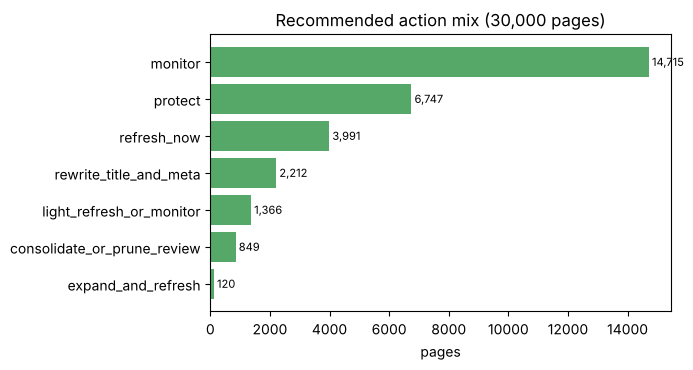

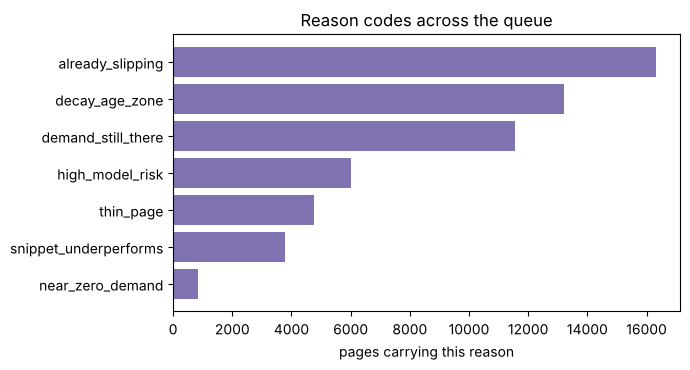

work/outputs/action_queue.csv                           4,541,010 bytes
work/outputs/action_queue_top20_public.json                 5,888 bytes
work/outputs/w07_playbook_metrics.json                      1,618 bytes
work/figures/w07_action_mix.png                            60,098 bytes
work/figures/w07_reason_codes.png                          55,160 bytes
work/figures/w07_decay_by_age.png                          53,822 bytes


In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

# 1) The full ranked queue -> work/outputs/ (CSV stays out of git by design; this cell regenerates it)
export_cols = ["rank", "content_id", "archetype_action", "risk_next30", "priority_score", "reason_codes",
               "impressions_last_30d", "clicks_last_30d", "content_age_days", "word_count", "content_type", "main_intent"]
queue[export_cols].to_csv("work/outputs/action_queue.csv", index=False)

# 2) Public-safe top-20 for the paper (no ids)
top20 = queue[["rank", "archetype_action", "risk_next30", "impressions_last_30d", "clicks_last_30d",
               "content_age_days", "word_count", "content_type", "reason_codes"]].head(20).round(3)
top20.to_json("work/outputs/action_queue_top20_public.json", orient="records", indent=1)

# 3) Figures the paper reuses
mix = df["archetype_action"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(mix.index, mix.values, color="#55A868")
for i, v in enumerate(mix.values):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
ax.set_xlabel("pages"); ax.set_title("Recommended action mix (30,000 pages)")
plt.tight_layout(); plt.savefig("work/figures/w07_action_mix.png", dpi=150); plt.show()

rc = pd.Series([r for s in df["reason_codes"] for r in s.split("|") if r != "none"]).value_counts().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(rc.index, rc.values, color="#8172B2"); ax.set_xlabel("pages carrying this reason")
ax.set_title("Reason codes across the queue"); plt.tight_layout()
plt.savefig("work/figures/w07_reason_codes.png", dpi=150); plt.show()

# 4) Metrics JSON = the receipt the paper's numbers trace back to
summary = {
    "model": "LogisticRegression (window-aligned features, see w06 + capstone)",
    "fold_precision_at_50": [round(float(v), 3) for v in fold_p50],
    "validation": "GroupKFold(5) by client_id, out-of-fold",
    "base_rate": round(float(y.mean()), 4),
    "backtest_precision_at_50": round(float(mu.precision_at_k(y, oof_backtest, 50)), 4),
    "backtest_precision_at_200": round(float(mu.precision_at_k(y, oof_backtest, 200)), 4),
    "action_mix": df["archetype_action"].value_counts().to_dict(),
    "reason_code_counts": rc.sort_values(ascending=False).to_dict(),
    "decay_by_age": {str(k): round(float(v), 4) for k, v in decay["share_declining"].items()},
    "retrain_triggers": TRIGGERS,
}
with open("work/outputs/w07_playbook_metrics.json", "w") as f:
    json.dump(summary, f, indent=2)
for p in ["work/outputs/action_queue.csv", "work/outputs/action_queue_top20_public.json", "work/outputs/w07_playbook_metrics.json",
          "work/figures/w07_action_mix.png", "work/figures/w07_reason_codes.png", "work/figures/w07_decay_by_age.png"]:
    print(f"{p:55s} {os.path.getsize(p):>9,} bytes")

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.